## **Import Packages**

In [1]:
import numpy as np
import pandas as pd 

import os
import glob
import matplotlib.pyplot as plt

from tqdm import tqdm

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

import torchvision.io as io
import torchvision.models as models
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

## **Import data & Display Some Images**

In [2]:
train_path = '/kaggle/input/competitions/state-farm-distracted-driver-detection/imgs/train'
for folder in glob.glob(train_path+'/*'):
    folder_name = folder.split('/')[-1]
    print(f'{folder_name} : {len(os.listdir(folder))} images')

c5 : 2312 images
c7 : 2002 images
c8 : 1911 images
c2 : 2317 images
c6 : 2325 images
c4 : 2326 images
c3 : 2346 images
c1 : 2267 images
c9 : 2129 images
c0 : 2489 images


> 데이터가 거의 balanced 하다

In [3]:
classes = {
    'c0': 'safe driving',
    'c1': 'texting - right',
    'c2': 'talking on the phone - right',
    'c3': 'texting - left',
    'c4': 'talking on the phone - left',
    'c5': 'operating the radio',
    'c6': 'drinking',
    'c7': 'reaching behind',
    'c8': 'hair and makeup',
    'c9': 'talking to passenger'
}

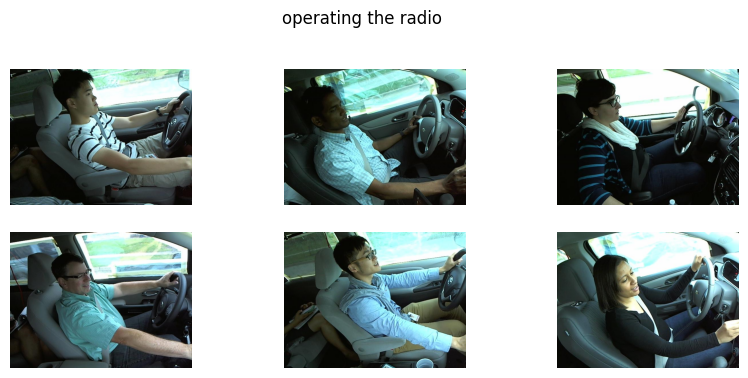

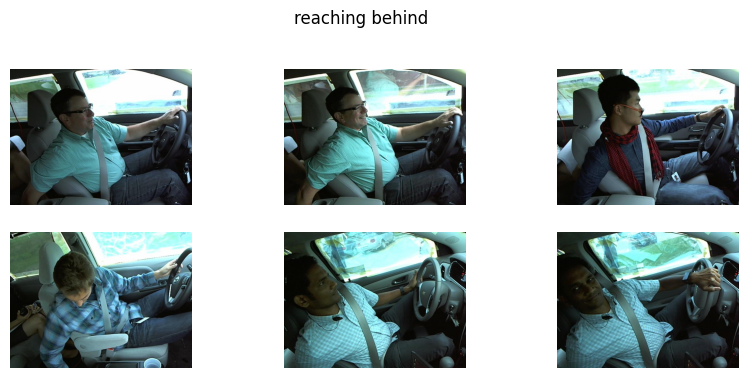

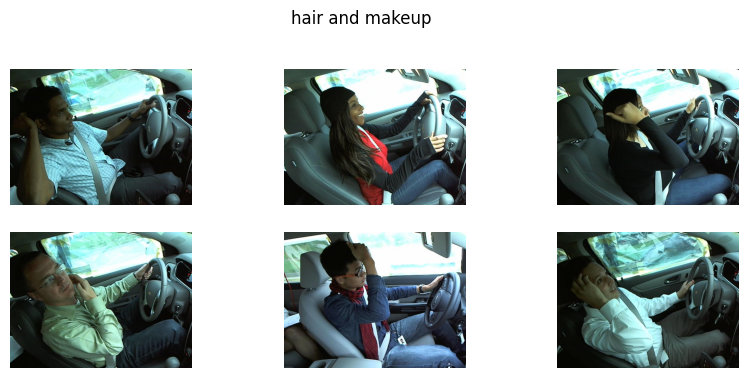

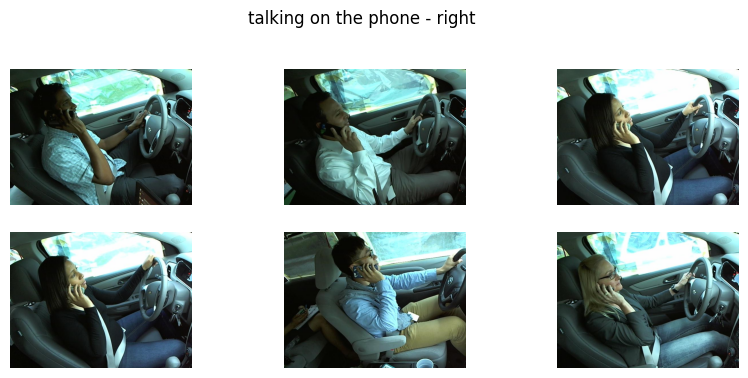

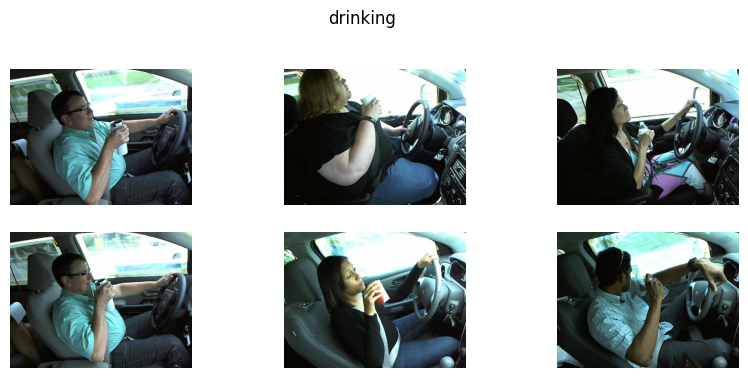

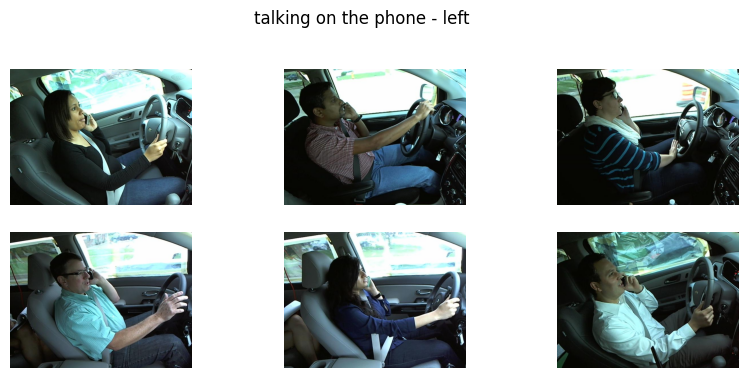

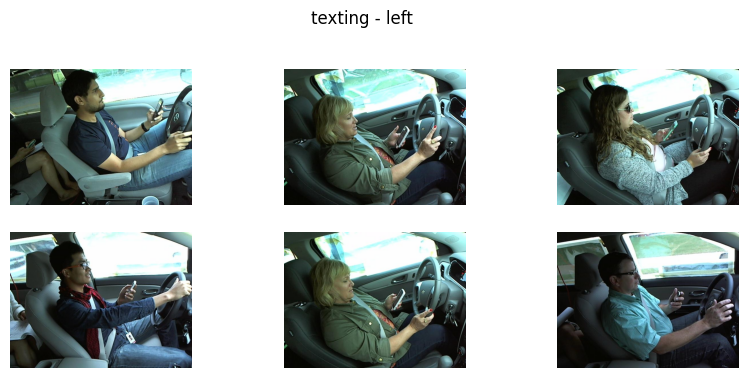

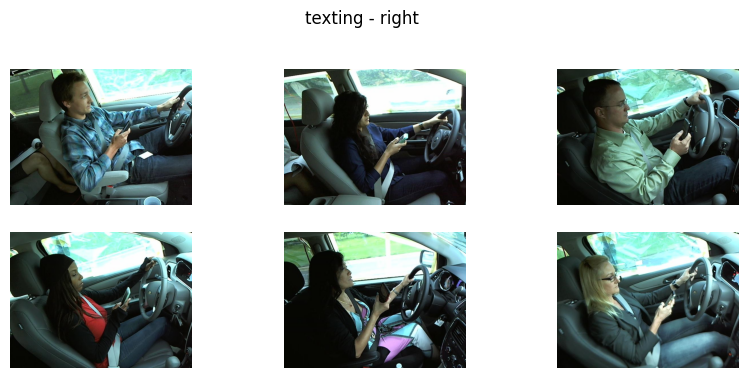

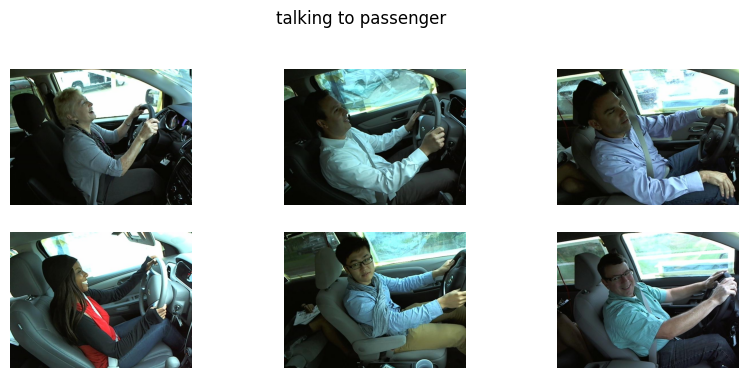

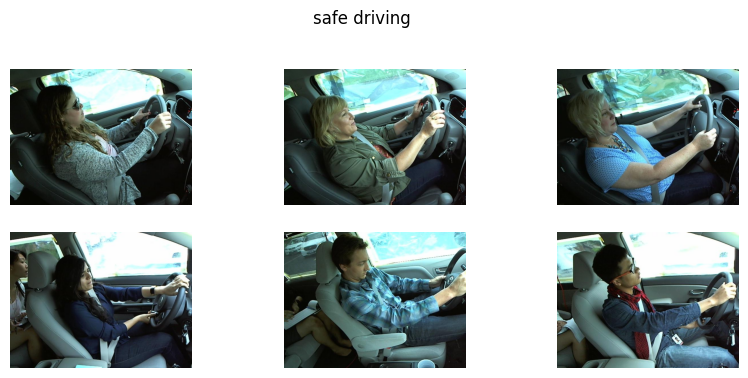

In [4]:
def show_images(folder_path, num):
    """
    Description:
        Display a random selection of images from the specified folder path.

    Parameters:
        - folder_path (str): The path to the folder containing the images.
        - num (int): The number of images to display.

    Returns:
        None
    """
    images = glob.glob(folder_path+'/*')
    selected_images = np.random.choice(images, num, replace=False)
    
    fig = plt.figure(figsize=(10, 6))
    columns = 3
    rows = (len(selected_images) // columns) + 1
    for i, image_file in enumerate(selected_images):
        img = plt.imread(image_file)
        ax = fig.add_subplot(rows, columns, i+1)
        ax.imshow(img)
        ax.axis('off')
    class_ = folder_path.split('/')[-1]
    plt.suptitle(classes[class_])
    plt.show()

# show some random images from each class 
for folder in glob.glob(train_path+'/*'):
      if os.path.isdir(folder):
          show_images(folder, 6)

In [5]:
img_path = '/kaggle/input/competitions/state-farm-distracted-driver-detection/imgs/train/c1/img_100021.jpg'
img = io.read_image(img_path)
img.shape

torch.Size([3, 480, 640])

## **BaseLine Dense Model**

In [6]:
class BaselineDenseModel(nn.Module):
    def __init__(self, input_size, num_classes):
        super(BaselineDenseModel, self).__init__()
        self.fc1 = nn.Linear(input_size, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 64)
        self.fc4 = nn.Linear(64, 32)
        self.fc5 = nn.Linear(32, num_classes)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=1)
        
    def forward(self, x):
        x = x.view(x.size(0), -1) # flatten the input
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.relu(self.fc3(x))
        x = self.relu(self.fc4(x))
        x = self.fc5(x)
        return self.softmax(x)


input_size = 480*640*3
num_classes = 10

model = BaselineDenseModel(input_size, num_classes)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

## **Data Augmentation**

In [7]:
train_transform = transforms.Compose([
    transforms.Resize((480, 640)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=10),
    transforms.RandomAffine(degrees=0, translate=(0.1,0.1), scale=(1.0, 1.2)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((480, 640)),  
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [8]:
dataset = datasets.ImageFolder(root=train_path, transform=train_transform)

In [9]:
dataset

Dataset ImageFolder
    Number of datapoints: 22424
    Root location: /kaggle/input/competitions/state-farm-distracted-driver-detection/imgs/train
    StandardTransform
Transform: Compose(
               Resize(size=(480, 640), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
               RandomAffine(degrees=[0.0, 0.0], translate=(0.1, 0.1), scale=(1.0, 1.2))
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           )

In [10]:
class2idx = dataset.class_to_idx
class_indices = {v:k for k, v in class2idx.items()}
class_indices

{0: 'c0',
 1: 'c1',
 2: 'c2',
 3: 'c3',
 4: 'c4',
 5: 'c5',
 6: 'c6',
 7: 'c7',
 8: 'c8',
 9: 'c9'}

In [11]:
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

In [12]:
# Split the dataset into training and validation sets
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

In [13]:
train_dataset.dataset.transform = train_transform
val_dataset.dataset.transform = test_transform

> 이 데이터셋의 문제는 별도의 validation set 없이 train 폴더만 존재한다는 것. 이를 해결하기 위해 random_split을 사용하여 train 데이터를 train subset과 validation subset으로 분할.

> 하지만 이 과정에서 random rotation이나 horizontal flip과 같은 동일한 data augmentation이 train set과 validation set 모두에 적용되는 문제가 발생.

> 이를 해결하기 위해 transform pipeline을 수정하여, train 데이터에는 특정 augmentation을 적용하고, validation 데이터 또는 새로운 데이터에는 별도의 전처리만 적용하도록 변경.

In [14]:
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

In [15]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [16]:
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=10, device='cuda'):
    """
    Description:
        Train the given model using the provided data loaders and optimization parameters.

    Parameters:
        - model (torch.nn.Module): The neural network model to train.
        - train_loader (torch.utils.data.DataLoader): DataLoader for training data.
        - val_loader (torch.utils.data.DataLoader): DataLoader for validation data.
        - criterion (torch.nn.Module): The loss function.
        - optimizer (torch.optim.Optimizer): The optimizer used for updating model parameters.
        - num_epochs (int): Number of training epochs (default: 10).
        - device (str): Device to run the training on (default: 'cuda').

    Returns:
        - model (torch.nn.Module): The trained model.
        - history (dict): A dictionary containing training history with keys:
            - 'train_loss': List of training losses for each epoch.
            - 'train_acc': List of training accuracies for each epoch.
            - 'val_loss': List of validation losses for each epoch.
            - 'val_acc': List of validation accuracies for each epoch.

    """
    
    model.to(device)
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    
    for epoch in tqdm(range(num_epochs)):
        # Training phase
        model.train()
        train_loss = 0.0
        correct_train = 0
        total_train_images = 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            _, predicted = torch.max(outputs.data, dim=1)
            correct_train += (predicted == labels).sum().item()
            total_train_images += labels.size(0)
            

        train_accuracy = 100 * correct_train / total_train_images
        avg_train_loss = train_loss / len(train_loader)

        # Validation phase
        model.eval()
        val_loss = 0.0
        correct_val = 0
        total_val_images = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                correct_val += (predicted == labels).sum().item()
                total_val_images += labels.size(0)
                

        val_accuracy = 100 * correct_val / total_val_images
        avg_val_loss = val_loss / len(val_loader)

        # Print epoch statistics
        print(f"Epoch [{epoch+1}/{num_epochs}]\nTrain Loss: {avg_train_loss:.4f}, Train Acc: {train_accuracy:.2f}%, Val Loss: {avg_val_loss:.4f}, Val Acc: {val_accuracy:.2f}%")

        # Save history
        history['train_loss'].append(avg_train_loss)
        history['train_acc'].append(train_accuracy)
        history['val_loss'].append(avg_val_loss)
        history['val_acc'].append(val_accuracy)

    return model, history

In [17]:
def plot_performance(history):
    """
    Description:
        Plot the training and validation loss, as well as training and validation accuracy over epochs.

    Parameters:
        - history (dict): A dictionary containing training history with keys:
        - 'train_loss': List of training losses for each epoch.
        - 'train_acc': List of training accuracies for each epoch.
        - 'val_loss': List of validation losses for each epoch.
        - 'val_acc': List of validation accuracies for each epoch.

    Returns:
        None
    """
    
    epochs = range(1, len(history['train_loss']) + 1)

    # Plot loss
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history['train_loss'], 'b-', label='Training Loss')
    plt.plot(epochs, history['val_loss'], 'r-', label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    # Plot accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history['train_acc'], 'b-', label='Training Accuracy')
    plt.plot(epochs, history['val_acc'], 'r-', label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy (%)')
    plt.legend()

    plt.tight_layout()
    plt.show()

## **BaseLine CNN**

In [18]:
class BaselineCNN(nn.Module):
    def __init__(self, num_classes):
        super(BaselineCNN, self).__init__()
        self.conv=nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, stride=1, padding=1)
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(64 * 37 * 37, 512)  # Adjusted input size based on the output of conv2
        self.fc2 = nn.Linear(512, num_classes)

    # def forward(self, x):
    #     identity=torch.relu(self.conv(x))
    #     x = torch.relu(self.conv1(x))
    #     x = (torch.relu(self.conv2(x))
    #     x=self.pool(self.pool(x+identity))
        
    #     x = x.view(-1, 64 * 37 * 37)  # Adjusted reshape based on the output size of conv2
    #     x = torch.relu(self.fc1(x))
    #     x = self.fc2(x)
    #     return x
    def forward(self, x):
        # identity path (projection to 64 channels)
        identity = torch.relu(self.conv(x))        # (B, 64, H, W)
    
        # residual path
        out = torch.relu(self.conv1(x))             # (B, 32, H, W)
        out = torch.relu(self.conv2(out))           # (B, 64, H, W)
    
        # residual addition (shapes now match)
        out = out + identity
    
        # downsampling AFTER residual addition
        out = self.pool(self.pool(out))
    
        out = out.view(out.size(0), -1)
        out = torch.relu(self.fc1(out))
        out = self.fc2(out)
    
        return out


model = BaselineCNN(num_classes=10)

In [19]:
train_transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=10),
    transforms.RandomAffine(degrees=0, translate=(0.1,0.1), scale=(1.0, 1.2)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((150, 150)),  
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [20]:
dataset = datasets.ImageFolder(root=train_path, transform=train_transform)

In [21]:
dataset

Dataset ImageFolder
    Number of datapoints: 22424
    Root location: /kaggle/input/competitions/state-farm-distracted-driver-detection/imgs/train
    StandardTransform
Transform: Compose(
               Resize(size=(150, 150), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
               RandomAffine(degrees=[0.0, 0.0], translate=(0.1, 0.1), scale=(1.0, 1.2))
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           )

In [22]:
class2idx = dataset.class_to_idx
class_indices = {v:k for k, v in class2idx.items()}
class_indices

{0: 'c0',
 1: 'c1',
 2: 'c2',
 3: 'c3',
 4: 'c4',
 5: 'c5',
 6: 'c6',
 7: 'c7',
 8: 'c8',
 9: 'c9'}

In [23]:
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

In [24]:
# Split the dataset into training and validation sets
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

In [25]:
train_dataset.dataset.transform = train_transform
val_dataset.dataset.transform = test_transform

In [26]:
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

> 여기서 발생한 문제는 이미지 크기가 너무 커서 메모리 부족(memory crash)이 발생하는 것으로 보임.  

> 이 문제를 해결하기 위해 batch size를 줄이고 모델의 구조를 단순화해 보았지만, 문제가 계속 발생.  

> 해결 방법으로 이미지 크기를 기존 (480, 640)에서 (150, 150)으로 축소(resizing)하였고, 이를 통해 메모리 문제가 해결.

In [27]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

In [28]:
trained_model, history = train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=6)

 17%|█▋        | 1/6 [02:55<14:35, 175.00s/it]

Epoch [1/6]
Train Loss: 1.6101, Train Acc: 85.58%, Val Loss: 0.0680, Val Acc: 98.28%


 33%|███▎      | 2/6 [05:51<11:42, 175.62s/it]

Epoch [2/6]
Train Loss: 0.0460, Train Acc: 98.76%, Val Loss: 0.0471, Val Acc: 98.55%


 50%|█████     | 3/6 [08:48<08:49, 176.53s/it]

Epoch [3/6]
Train Loss: 0.0369, Train Acc: 98.94%, Val Loss: 0.1260, Val Acc: 96.32%


... (2 outputs left out)

 83%|████████▎ | 5/6 [14:44<02:57, 177.33s/it]

Epoch [5/6]
Train Loss: 0.0125, Train Acc: 99.68%, Val Loss: 0.0211, Val Acc: 99.55%


100%|██████████| 6/6 [17:41<00:00, 176.86s/it]

Epoch [6/6]
Train Loss: 0.0331, Train Acc: 99.04%, Val Loss: 0.0336, Val Acc: 99.15%


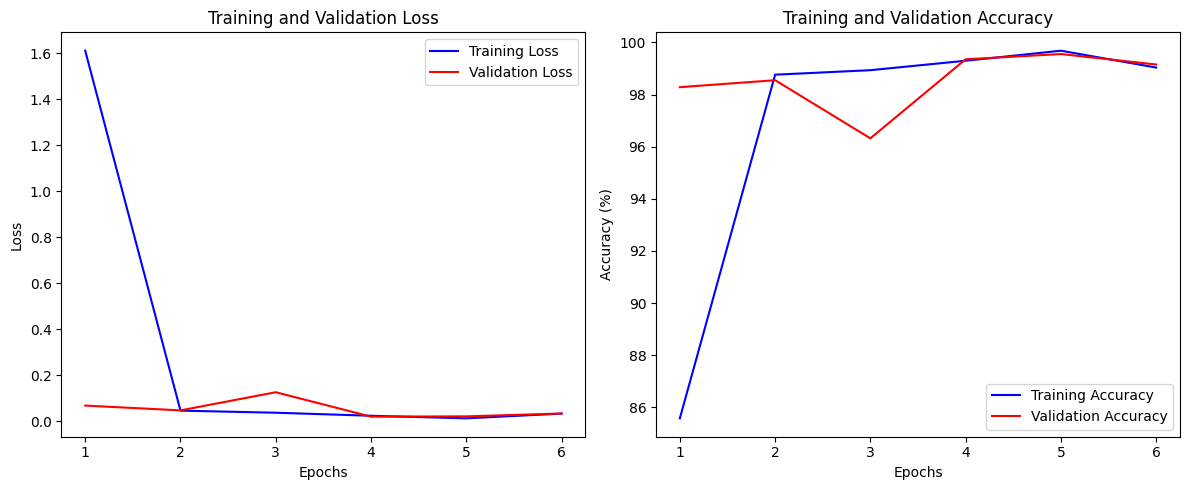

In [29]:
plot_performance(history)

## **Test model on Test Data**

In [53]:
from torch.utils.data import Dataset

class TestFolderDataset(Dataset):
  def __init__(self, paths, transform):
    self.paths = paths
    self.transform = transform

  def __len__(self):
    return len(self.paths)

  def __getitem__(self, idx):
    image = Image.open(self.paths[idx])
    return self.transform(image)

def predict_folder(folder_path, model, batch_size=128):
  img_paths = glob.glob(folder_path+'/*')
  loader = DataLoader(TestFolderDataset(img_paths, test_transform),
                      batch_size=batch_size, shuffle=False, num_workers=2)

  probabilities_per_image = []
  model.eval()
  with torch.no_grad():
    for batch in tqdm(loader):
      output = model(batch.to(device))
      probabilities = torch.softmax(output, dim=1)
      probabilities_per_image.extend(probabilities.tolist())

  images = [p.split('/')[-1] for p in img_paths]
  return images, probabilities_per_image

In [55]:
# Example usage
folder_path = '/kaggle/input/competitions/state-farm-distracted-driver-detection/imgs/test'
images, probabilities_per_image = predict_folder(folder_path, trained_model)

100%|██████████| 623/623 [05:32<00:00,  1.88it/s]


In [56]:
len(probabilities_per_image)

79726

In [57]:
df1 = pd.DataFrame({'img': images})
df2 = pd.DataFrame(probabilities_per_image, columns = ['c0', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c7', 'c8', 'c9'])
final_sub = pd.concat((df1, df2), axis=1)
final_sub

,img,c0,c1,c2,c3,c4,c5,c6,c7,c8,c9
0,img_96590.jpg,1.841046e-10,6.060028e-12,5.195275e-08,2.889666e-11,1.143131e-05,4.053548e-07,6.163538e-06,5.848314e-09,9.999779e-01,4.018041e-06
1,img_32366.jpg,5.858491e-14,3.868595e-10,1.566950e-09,1.148425e-10,1.685077e-04,9.924363e-01,3.010975e-06,3.666408e-11,3.515916e-08,7.392053e-03
2,img_99675.jpg,3.300197e-09,8.488684e-09,5.705894e-10,1.975473e-10,3.782917e-08,6.139289e-07,5.792469e-09,5.841768e-08,3.145246e-06,9.999962e-01
3,img_85937.jpg,5.352370e-10,3.264572e-16,5.670166e-16,1.286084e-13,1.001000e-06,9.999818e-01,1.559138e-14,1.125250e-13,1.248038e-09,1.723727e-05
4,img_73903.jpg,6.089705e-10,3.536938e-09,2.243429e-06,9.482891e-11,1.686774e-07,2.288137e-08,2.659558e-06,9.999945e-01,2.681785e-08,3.067054e-07
...,...,...,...,...,...,...,...,...,...,...,...
79721,img_109.jpg,2.201718e-10,4.455959e-09,5.749119e-06,1.055327e-06,2.098739e-07,1.414883e-03,2.357066e-15,1.503402e-09,4.084917e-02,9.577289e-01
79722,img_53257.jpg,1.763240e-06,1.479428e-07,2.249442e-10,9.998846e-01,4.591050e-06,2.516778e-07,1.389644e-10,1.554644e-08,1.061283e-04,2.510478e-06
79723,img_90376.jpg,1.359950e-17,8.038808e-02,4.538457e-10,1.600690e-02,8.716109e-14,5.423210e-02,1.176070e-03,7.587698e-09,4.829725e-10,8.481969e-01
79724,img_28000.jpg,8.218918e-10,9.517341e-10,1.674981e-09,7.281014e-07,3.183924e-06,9.556878e-01,8.118136e-05,3.302308e-09,2.027125e-04,4.402445e-02


In [58]:
final_sub.isnull().sum()

img    0
c0     0
c1     0
c2     0
c3     0
c4     0
c5     0
c6     0
c7     0
c8     0
c9     0
dtype: int64

In [59]:
final_sub.to_csv('final_sub.csv', index=False)

## **Transfer Learning**

In [60]:
transfer_model = models.resnet18(pretrained=True)
num = transfer_model.fc.in_features
transfer_model.fc = nn.Linear(num, 10)

trained_transfer_model, history = train_model(transfer_model, train_loader, val_loader, criterion, optimizer, num_epochs=6)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
 17%|█▋        | 1/6 [02:40<13:22, 160.48s/it]

Epoch [1/6]
Train Loss: 2.5840, Train Acc: 11.37%, Val Loss: 2.5798, Val Acc: 11.37%


 33%|███▎      | 2/6 [05:20<10:40, 160.13s/it]

Epoch [2/6]
Train Loss: 2.5835, Train Acc: 11.37%, Val Loss: 2.5860, Val Acc: 11.08%


 50%|█████     | 3/6 [08:07<08:10, 163.46s/it]

Epoch [3/6]
Train Loss: 2.5829, Train Acc: 11.03%, Val Loss: 2.5729, Val Acc: 11.35%


... (2 outputs left out)

 83%|████████▎ | 5/6 [13:27<02:40, 161.00s/it]

Epoch [5/6]
Train Loss: 2.5817, Train Acc: 11.17%, Val Loss: 2.5765, Val Acc: 11.35%


100%|██████████| 6/6 [16:06<00:00, 161.01s/it]

Epoch [6/6]
Train Loss: 2.5824, Train Acc: 11.29%, Val Loss: 2.5918, Val Acc: 11.44%
